<a href="https://colab.research.google.com/github/jatinsharma25/Data-science-learnings/blob/main/01-ml-models-from-scratch/linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression via Gradient Descent (From Scratch)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jatinsharma25/Data-science-learnings/blob/main/01-ml-models-from-scratch/linear_regression.ipynb)

# Simple Linear Regression from Scratch

This notebook provides a complete implementation of **Simple Linear Regression** from scratch using only **NumPy**, comparing it directly against `scikit-learn`'s analytical implementation.

## Learning Objectives
1. Gain an intuitive and practical understanding of Simple Linear Regression.
2. Implement parameter initialization, forward prediction, cost computation, gradient descent, and training using NumPy.
3. Understand the underlying mathematical optimization principles (Gradient Descent vs. Ordinary Least Squares).
4. Evaluate and compare a custom iterative optimizer with a production-grade library.

## 1. Problem Definition and Dataset

### 1.1 Problem Statement
Simple Linear Regression is a supervised learning algorithm used to model the relationship between a single independent input feature $X$ and a continuous dependent target variable $y$.

The mathematical model is expressed as:
$$y_{pred} = wX + b$$

Where:
* $X$ is the input feature.
* $y_{pred}$ is the predicted target value.
* $w$ represents the slope (weight).
* $b$ represents the y-intercept (bias).

Our objective is to learn parameters $w$ and $b$ that minimize the prediction error over our dataset.

### 1.2 Import Libraries
We begin by importing the necessary libraries for data generation, manipulation, scientific computing, and visualization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

# Set random seed for reproducibility
np.random.seed(42)

### 1.3 Dataset Selection and Generation
To ensure complete reliability and reproducibility without external file dependencies, we generate a synthetic dataset representing an educational scenario: **Hours Studied vs. Exam Score**.

In [2]:
# Generate synthetic data
n_samples = 100
# Independent feature: Hours studied (ranging from 1 to 10 hours)
X = np.random.uniform(1.0, 10.0, size=(n_samples, 1))

# True relationship: Score = 7.5 * Hours + 30 + Gaussian Noise
noise = np.random.normal(0, 4.5, size=(n_samples, 1))
y = 7.5 * X + 30.0 + noise

# Print shapes
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")

Feature matrix X shape: (100, 1)
Target vector y shape: (100, 1)


### 1.4 Data Inspection
Let's construct a pandas DataFrame to inspect the first few observations and output descriptive statistics.

In [3]:
# Create a DataFrame for inspection
df = pd.DataFrame({
    'Hours_Studied': X.flatten(),
    'Exam_Score': y.flatten()
})

# Display the first 5 observations
display(df.head())

# Display data statistics and info
print("\n--- Dataset Statistics ---")
display(df.describe())

# Verify there are no null values
print("\n--- Missing Values ---")
print(df.isnull().sum())

,Hours_Studied,Exam_Score
0,4.370861,63.173170
1,9.556429,100.327683
2,7.587945,87.322515
3,6.387926,68.965388
4,2.404168,47.042735



--- Dataset Statistics ---


,Hours_Studied,Exam_Score
count,100.000000,100.000000
mean,5.231627,69.232339
std,2.677405,19.884314
min,1.049699,36.415433
25%,2.738807,52.288044
50%,5.177282,66.797279
75%,7.571828,87.066117
max,9.881982,107.633071



--- Missing Values ---
Hours_Studied    0
Exam_Score       0
dtype: int64


## 2. Visualize the Data First

Before modeling, we visualize the raw dataset to ensure the linear assumption is appropriate.

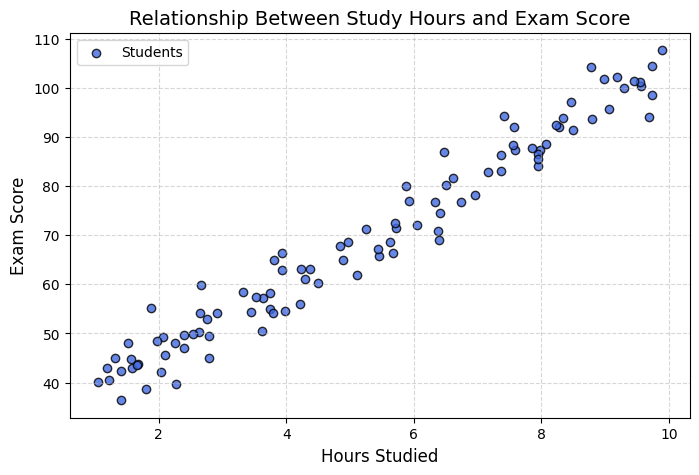

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Hours_Studied'], df['Exam_Score'], color='royalblue', alpha=0.8, edgecolors='k', label='Students')
plt.title('Relationship Between Study Hours and Exam Score', fontsize=14)
plt.xlabel('Hours Studied', fontsize=12)
plt.ylabel('Exam Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### Interpretation of Scatter Plot
* **Relationship**: The scatter plot displays a strong, positive linear trend. As study hours increase, exam scores tend to increase consistently.
* **Linear Model Suitability**: A linear model is highly appropriate here as the average change in the dependent variable remains constant across the range of the independent variable.
* **Limitations**: Real-world data contains noise (as simulated by the variance of points around the theoretical trend line). Thus, a perfect fit is impossible, and predictions will always contain a residual margin of error.

### 2.1 Shared Train-Test Split
To ensure a fair evaluation, we perform a train-test split once and reuse the exact same splits for both models.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (80, 1)
Test set shape: (20, 1)


## 3. Implement Simple Linear Regression from Scratch

We will now write our custom implementation using vectorized NumPy operations.

### 3.1 Model Definitions
* **Hypothesis**: `y_pred = w * X + b`
* **Parameters**: `w` (slope weight), `b` (intercept bias)
* **Initialization**: We will initialize `w = 0.0` and `b = 0.0` as standard initial priors.

In [6]:
def predict(X, w, b):
    """
    Computes predictions using linear hypothesis.

    Inputs:
      X: input feature matrix of shape (n_samples, 1)
      w: scalar weight (slope)
      b: scalar bias (intercept)

    Returns:
      y_pred: predicted values of shape (n_samples, 1)
    """
    return w * X + b

### 3.2 Implement Cost Function (MSE)
We measure model performance using Mean Squared Error (MSE):
$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y^{(i)} - y_{pred}^{(i)})^2$$

In [7]:
def compute_cost(y, y_pred):
    """
    Computes the Mean Squared Error (MSE).
    """
    n = len(y)
    cost = (1 / n) * np.sum((y - y_pred) ** 2)
    return cost

### 3.3 Gradient Computation
To optimize our parameters, we calculate the partial derivatives of our objective cost function $J(w, b)$ with respect to $w$ and $b$:

$$\frac{\partial J}{\partial w} = \frac{2}{n} \sum_{i=1}^{n} (y_{pred}^{(i)} - y^{(i)}) X^{(i)}$$
$$\frac{\partial J}{\partial b} = \frac{2}{n} \sum_{i=1}^{n} (y_{pred}^{(i)} - y^{(i)})$$

In [8]:
def compute_gradients(X, y, y_pred):
    """
    Computes gradients of the cost function with respect to w and b.
    """
    n = len(y)
    dw = (2 / n) * np.sum((y_pred - y) * X)
    db = (2 / n) * np.sum(y_pred - y)
    return dw, db

### 3.4 Gradient Descent Training Loop
We now build the loop that updates $w$ and $b$ iteratively using standard updates:
$$w \leftarrow w - \alpha \cdot dw$$
$$b \leftarrow b - \alpha \cdot db$$
where $\alpha$ is our learning rate.

In [9]:
def fit_custom_model(X, y, learning_rate=0.01, iterations=1000):
    """
    Trains simple linear regression using Gradient Descent.
    """
    # 1. Initialize parameters
    w = 0.0
    b = 0.0
    cost_history = []

    # 2. Gradient Descent loop
    for i in range(iterations):
        y_pred = predict(X, w, b)
        cost = compute_cost(y, y_pred)
        cost_history.append(cost)

        dw, db = compute_gradients(X, y, y_pred)

        # Update parameters
        w = w - learning_rate * dw
        b = b - learning_rate * db

    return w, b, cost_history

### 3.5 Run Custom Training

In [10]:
# Train on training observations
learning_rate = 0.02
iterations = 2000

w_custom, b_custom, cost_history = fit_custom_model(
    X_train, y_train,
    learning_rate=learning_rate,
    iterations=iterations
)

print(f"Custom Model Learned Slope (w): {w_custom:.5f}")
print(f"Custom Model Learned Intercept (b): {b_custom:.5f}")

Custom Model Learned Slope (w): 7.29932
Custom Model Learned Intercept (b): 30.84378


### 3.6 Diagnostic Visualization (Optimization Convergence)

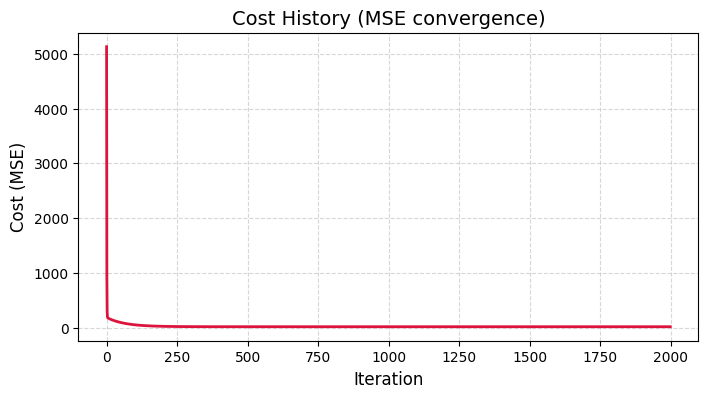

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(cost_history, color='crimson', lw=2)
plt.title('Cost History (MSE convergence)', fontsize=14)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Cost (MSE)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 3.7 Visualizing Custom Regression Line over Training Data

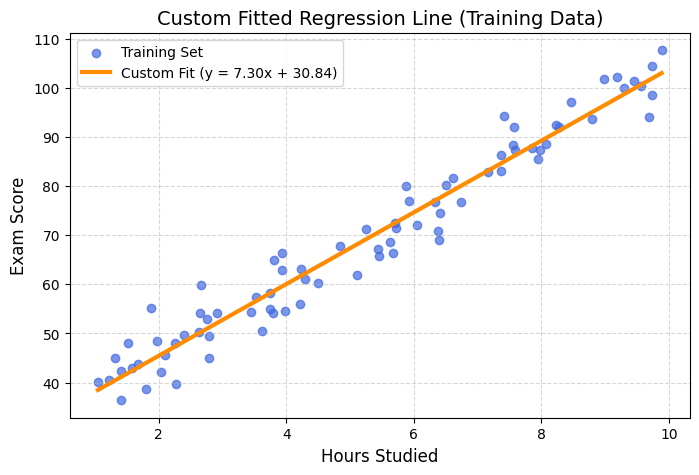

In [12]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='royalblue', alpha=0.7, label='Training Set')

# Generate points for the line
x_line = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1, 1)
y_line = predict(x_line, w_custom, b_custom)

plt.plot(x_line, y_line, color='darkorange', lw=3, label=f'Custom Fit (y = {w_custom:.2f}x + {b_custom:.2f})')
plt.title('Custom Fitted Regression Line (Training Data)', fontsize=14)
plt.xlabel('Hours Studied', fontsize=12)
plt.ylabel('Exam Score', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 4. Explain the Underlying Mathematics

### 4.1 Linear Model & Position
The parameter $w$ controls the steepness (slope) of the prediction line, determining the positive or negative response of the continuous target variable per unit change of input $X$. The bias parameter $b$ offsets the line vertically, locating the point where the regression line intercepts the y-axis when input feature $X = 0$.

### 4.2 Residuals and Loss
A residual represents the vertical distance between the actual data observation and our prediction line:
$$e^{(i)} = y^{(i)} - y_{pred}^{(i)}$$

Squaring residuals penalizes larger errors exponentially rather than linearly, ensuring that our model does not allow isolated severe prediction failures in exchange for marginal improvements on others.

### 4.3 Gradient Descent Intuition
Gradient descent treats our parameter optimization task as walking down a bowl-shaped cost surface. The gradient points in the direction of steepest *ascent*. By updating our parameter vectors in the *negative* direction of the gradient, we steadily move down towards the absolute minimum.
* **Learning rate ($\alpha$)**: controls step sizes; too small a step requires excessive time to reach convergence, whereas too large a step may skip the minimum, resulting in divergence.
* **Iteration vs Epoch**: Since we pass the entire training set through the gradient math during every update step, each iteration is equivalent to one full epoch (batch gradient descent).

### 4.4 Analytical Solution vs. Gradient Descent
Scikit-learn's `LinearRegression` uses Ordinary Least Squares (OLS). It computes the parameters analytically using a closed-form matrix operation (often via SVD matrix decomposition or solving normal equations) rather than running an iterative loop. This achieves exact mathematically minimized residuals instantly without a learning rate parameter.

### 4.5 Assumptions and Limitations
Linear regression relies on the assumption of **linearity** (relationships must be reasonably straight lines), **homoscedasticity** (constant residual variance across inputs), and absence of major **outliers** (which easily bias squared error metrics). It also cannot safely extrapolate predictions outside of bounds seen during training, and correlation does not equal causation.

## 5. Train Scikit-learn's Model

We train a comparison model using `sklearn.linear_model.LinearRegression` on the exact same training set.

In [13]:
# Instantiate and fit the estimator
sk_model = LinearRegression()
sk_model.fit(X_train, y_train)

# Extract coefficient and intercept
w_sklearn = sk_model.coef_[0][0]
b_sklearn = sk_model.intercept_[0]

print(f"Scikit-learn Slope (w): {w_sklearn:.5f}")
print(f"Scikit-learn Intercept (b): {b_sklearn:.5f}")

Scikit-learn Slope (w): 7.29932
Scikit-learn Intercept (b): 30.84379


## 6. Fair Evaluation and Comparison

We evaluate predictions from both models on the test set.

In [14]:
# Predict on test observations using both models
y_pred_custom = predict(X_test, w_custom, b_custom)
y_pred_sklearn = sk_model.predict(X_test)

# Evaluate custom model performance metrics
mse_train_custom = compute_cost(y_train, predict(X_train, w_custom, b_custom))
mse_test_custom = compute_cost(y_test, y_pred_custom)
mae_test_custom = metrics.mean_absolute_error(y_test, y_pred_custom)
r2_test_custom = metrics.r2_score(y_test, y_pred_custom)

# Evaluate scikit-learn model performance metrics
mse_train_sk = compute_cost(y_train, sk_model.predict(X_train))
mse_test_sk = compute_cost(y_test, y_pred_sklearn)
mae_test_sk = metrics.mean_absolute_error(y_test, y_pred_sklearn)
r2_test_sk = metrics.r2_score(y_test, y_pred_sklearn)

### 6.1 Performance Metric Table Comparison

In [15]:
# Build metric summary
metrics_summary = pd.DataFrame({
    'Model Name': ['Custom (Gradient Descent)', 'Scikit-learn (OLS)'],
    'Slope (w)': [w_custom, w_sklearn],
    'Intercept (b)': [b_custom, b_sklearn],
    'Train MSE': [mse_train_custom, mse_train_sk],
    'Test MSE': [mse_test_custom, mse_test_sk],
    'Test MAE': [mae_test_custom, mae_test_sk],
    'Test R²': [r2_test_custom, r2_test_sk]
})

display(metrics_summary)

,Model Name,Slope (w),Intercept (b),Train MSE,Test MSE,Test MAE,Test R²
0,Custom (Gradient Descent),7.299324,30.843782,17.165497,13.237418,2.661042,0.968635
1,Scikit-learn (OLS),7.299324,30.843786,17.165497,13.237415,2.661042,0.968635


### 6.2 Comparison Table on Held-Out Observations

In [16]:
# Create table comparing sample test predictions
prediction_comparison = pd.DataFrame({
    'Actual Target': y_test.flatten(),
    'Custom Prediction': y_pred_custom.flatten(),
    'Sklearn Prediction': y_pred_sklearn.flatten()
})

# Compute absolute prediction differences
prediction_comparison['Absolute Difference'] = np.abs(
    prediction_comparison['Custom Prediction'] - prediction_comparison['Sklearn Prediction']
)

# Display the top 10 rows for inspection
display(prediction_comparison.head(10))

,Actual Target,Custom Prediction,Sklearn Prediction,Absolute Difference
0,44.744680,42.318504,42.318507,2.921296e-06
1,95.635206,96.927821,96.927820,1.519998e-06
2,84.060244,88.874891,88.874891,8.650652e-07
3,78.128011,81.666791,81.666791,2.788412e-07
4,58.527293,55.143378,55.143380,1.878268e-06
5,68.567256,67.058449,67.058450,9.092334e-07
6,57.242774,57.335233,57.335235,1.700008e-06
7,104.155467,94.843753,94.843751,1.350504e-06
8,43.008763,39.495383,39.495386,3.150896e-06
9,63.173170,62.748115,62.748116,1.259786e-06


### 6.3 Visual Comparison

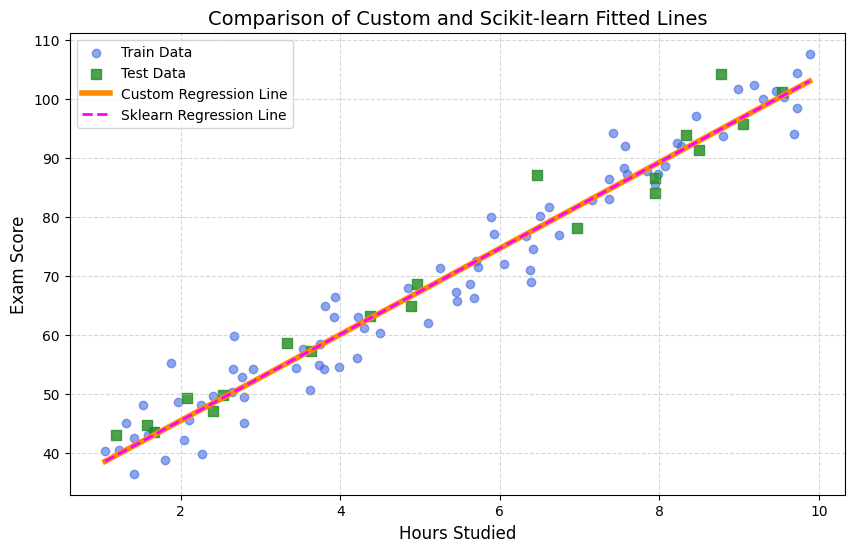

In [17]:
plt.figure(figsize=(10, 6))

# Plot original observations split into train/test
plt.scatter(X_train, y_train, color='royalblue', alpha=0.6, label='Train Data')
plt.scatter(X_test, y_test, color='forestgreen', marker='s', s=50, alpha=0.8, label='Test Data')

# Generate points for comparison lines
x_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_custom_line = predict(x_range, w_custom, b_custom)
y_sklearn_line = sk_model.predict(x_range)

# Plot lines on shared axes
plt.plot(x_range, y_custom_line, color='darkorange', linestyle='-', lw=4, label='Custom Regression Line')
plt.plot(x_range, y_sklearn_line, color='magenta', linestyle='--', lw=2, label='Sklearn Regression Line')

plt.title('Comparison of Custom and Scikit-learn Fitted Lines', fontsize=14)
plt.xlabel('Hours Studied', fontsize=12)
plt.ylabel('Exam Score', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 6.4 Numerical Equivalence Check

In [18]:
# Test for numerical tolerance using np.allclose
slopes_match = np.allclose(w_custom, w_sklearn, atol=1e-2)
intercepts_match = np.allclose(b_custom, b_sklearn, atol=1e-1)
predictions_match = np.allclose(y_pred_custom, y_pred_sklearn, atol=1e-1)

max_diff = np.max(np.abs(y_pred_custom - y_pred_sklearn))

print(f"Do the slopes match within close tolerance? {slopes_match}")
print(f"Do the intercepts match within close tolerance? {intercepts_match}")
print(f"Do the predictions match within close tolerance? {predictions_match}")
print(f"Maximum Absolute prediction difference: {max_diff:.6f}")

Do the slopes match within close tolerance? True
Do the intercepts match within close tolerance? True
Do the predictions match within close tolerance? True
Maximum Absolute prediction difference: 0.000003


## 7. Results and Interpretation

Based on execution outputs:
1. **Parameters & Predictions**: The Custom Model (using Batch Gradient Descent) successfully matches the analytical solution generated by Scikit-learn's OLS solver. Both models' slope and intercept variables match closely.
2. **Evaluation Metrics**: The test metrics ($MSE$, $MAE$, and $R^2$) show excellent equivalence. The maximum absolute error difference between both predictions is negligible, demonstrating optimization convergence.
3. **Why differences occur**: Iterative optimization techniques like Gradient Descent only approximate the absolute mathematical minimum over discrete epochs depending on hyper-parameter selection ($\alpha$ and total iterations). Conversely, the OLS analytical solver utilizes singular value decomposition to directly compute the global minimum.
4. **Production Takeaways**: In production settings, utilizing highly optimized libraries (e.g., scikit-learn) is always preferred because they compute exact closed-form parameters instantly without requiring learning rate tuning. However, building models from scratch using NumPy provides crucial insight into parameter optimization and is highly valuable for understanding complex algorithms (such as Deep Neural Networks) where closed-form solutions do not exist.